# TP 4 : Évaluation, profilage et stabilité des clusters

**Ressource :** R3.13 - Maintenance Prédictive & Data Science  
**Séance 4 :** Évaluation et stabilité des partitions  
**Auteur :** Étudiant en informatique / Data Science  
**Graine aléatoire :** seed = 42

---

## Objectifs du TP

Dans les TP 2 et 3, j'ai segmenté les données avec K-means et CAH/DBSCAN.  
Dans ce quatrième TP, mon objectif est d'évaluer rigoureusement la qualité et la robustesse de ces partitions :
1. Calculer les métriques internes (Silhouette, Davies-Bouldin, Calinski-Harabasz) pour k allant de 2 à 8.
2. Comparer les clusters aux régimes experts (métriques externes : ARI, NMI, AMI, Pureté).
3. Tester la stabilité des partitions face aux graines aléatoires et au ré-échantillonnage (80 %).
4. Évaluer la stabilité temporelle entre la première et la seconde moitié de la journée.
5. Rédiger les fiches descriptives complètes des 4 segments obtenus pour k = 4.
6. Rédiger une note de synthèse et de décision pour le responsable de production.


## 0. Environnement et préparation des données

J'importe les modules nécessaires et je prépare la matrice de données standardisée `X_std` sur les 4 mesures physiques de procédé (`temperature`, `vibration`, `courant`, `cadence`).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score
)

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


In [2]:
data_path = Path("../data/atelier_connecte.csv")
if not data_path.exists():
    data_path = Path("data/atelier_connecte.csv")

df = pd.read_csv(data_path)
print(f"Dataset charge : {df.shape[0]} lignes et {df.shape[1]} colonnes")

mesures = ["temperature", "vibration", "courant", "cadence"]

# Imputation par la mediane et standardisation
imputer = SimpleImputer(strategy="median")
X_raw = imputer.fit_transform(df[mesures])

scaler = StandardScaler()
X_std = scaler.fit_transform(X_raw)

print(f"Matrice standardisee X_std : {X_std.shape}")


Dataset charge : 1728 lignes et 20 colonnes
Matrice standardisee X_std : (1728, 4)


---
## 1. Métriques internes (k = 2 à 8)

Les métriques internes évaluent la qualité géométrique du partitionnement sans utiliser d'étiquettes externes :
- **Coefficient de silhouette (à maximiser) :** mesure le compromis entre compacité interne et séparation avec le groupe voisin le plus proche (entre -1 et +1).
- **Indice de Davies-Bouldin (à minimiser) :** ratio moyen entre la dispersion interne de chaque paire de clusters et la distance séparant leurs centres. Plus la valeur est faible, plus les groupes sont séparés.
- **Indice de Calinski-Harabasz (à maximiser) :** ratio entre la dispersion inter-clusters et la dispersion intra-cluster, pondéré par les degrés de liberté. Plus la valeur est élevée, plus les clusters sont denses et écartés.


In [3]:
k_liste = list(range(2, 9))
res_internes = []

for k in k_liste:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_std)
    labels = km.labels_
    res_internes.append({
        "k": k,
        "Silhouette (max)": silhouette_score(X_std, labels),
        "Davies-Bouldin (min)": davies_bouldin_score(X_std, labels),
        "Calinski-Harabasz (max)": calinski_harabasz_score(X_std, labels)
    })

df_internes = pd.DataFrame(res_internes)
df_internes.round(3)


,k,Silhouette (max),Davies-Bouldin (min),Calinski-Harabasz (max)
0,2,0.489,0.734,2537.725
1,3,0.410,0.882,2333.184
2,4,0.390,0.895,2033.434
3,5,0.304,1.089,1894.978
4,6,0.247,1.272,1668.026
5,7,0.240,1.318,1523.066
6,8,0.241,1.289,1424.122


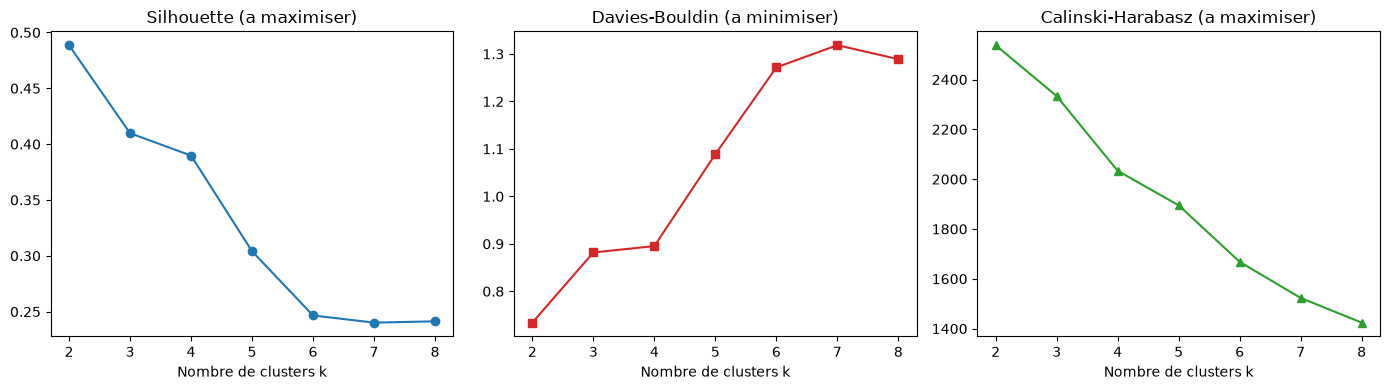

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(df_internes["k"], df_internes["Silhouette (max)"], marker="o", color="#1f77b4")
axes[0].set_title("Silhouette (a maximiser)")
axes[0].set_xlabel("Nombre de clusters k")

axes[1].plot(df_internes["k"], df_internes["Davies-Bouldin (min)"], marker="s", color="#d62728")
axes[1].set_title("Davies-Bouldin (a minimiser)")
axes[1].set_xlabel("Nombre de clusters k")

axes[2].plot(df_internes["k"], df_internes["Calinski-Harabasz (max)"], marker="^", color="#2ca02c")
axes[2].set_title("Calinski-Harabasz (a maximiser)")
axes[2].set_xlabel("Nombre de clusters k")

plt.tight_layout()
plt.show()


### Quel k désignent les métriques internes ?

En observant les critères et leur sens d'optimisation :
- Silhouette : maximale pour k = 2 (0.489).
- Davies-Bouldin : minimale pour k = 2 (0.734).
- Calinski-Harabasz : maximale pour k = 2 (2537.725).

Les 3 métriques internes s'accordent unanimement sur **k = 2**.  
D'un point de vue géométrique pur, le nuage de points se divise avant tout en deux grands ensembles très distants : les machines fonctionnant à charge modérée (M-01, M-02, M-05) d'une part, et les machines fortement sollicitées ou usées (M-03, M-04, M-06) d'autre part.


---
## 2. Métriques externes par rapport à `regime_reference` (k = 2 à 8)

Je compare maintenant les clusters prédits aux 5 diagnostics experts contenus dans la colonne `regime_reference` :
- **ARI (Adjusted Rand Index) :** accord entre deux partitions corrigé du hasard (1.0 pour accord parfait).
- **NMI (Normalized Mutual Information) :** quantité d'information partagée normalisée entre 0 et 1.
- **AMI (Adjusted Mutual Information) :** information mutuelle corrigée du hasard.
- **Pureté :** proportion d'observations appartenant à la classe majoritaire dans chaque groupe. On la calcule directement depuis la table de contingence `cont = pd.crosstab(df["regime_reference"], labels)` avec la formule : `cont.max(axis=0).sum() / len(df)`.


In [5]:
res_externes = []

for k in k_liste:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X_std)
    labels = km.labels_
    cont = pd.crosstab(df["regime_reference"], labels)
    purete = cont.max(axis=0).sum() / len(df)
    
    res_externes.append({
        "k": k,
        "ARI": adjusted_rand_score(df["regime_reference"], labels),
        "NMI": normalized_mutual_info_score(df["regime_reference"], labels),
        "AMI": adjusted_mutual_info_score(df["regime_reference"], labels),
        "Purete": purete
    })

df_externes = pd.DataFrame(res_externes)
df_externes.round(3)


,k,ARI,NMI,AMI,Purete
0,2,0.112,0.200,0.199,0.536
1,3,0.262,0.370,0.368,0.666
2,4,0.275,0.387,0.385,0.702
3,5,0.204,0.359,0.357,0.708
4,6,0.175,0.340,0.337,0.707
5,7,0.155,0.330,0.327,0.707
6,8,0.157,0.329,0.326,0.721


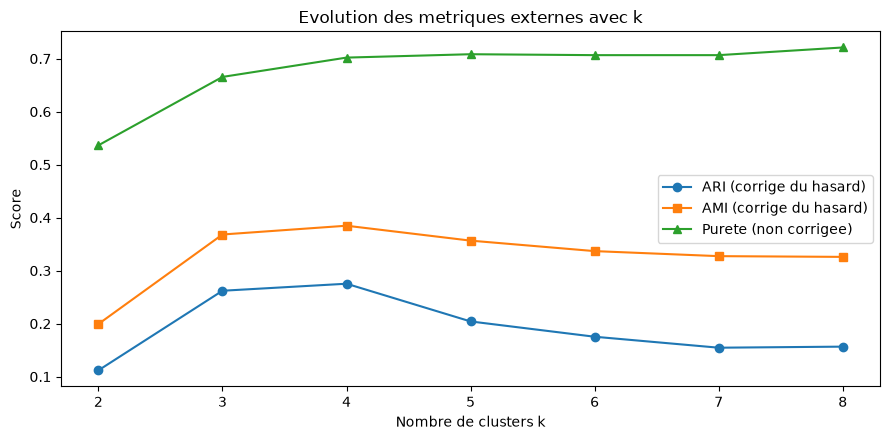

In [6]:
plt.figure(figsize=(9, 4.5))
plt.plot(df_externes["k"], df_externes["ARI"], marker="o", label="ARI (corrige du hasard)")
plt.plot(df_externes["k"], df_externes["AMI"], marker="s", label="AMI (corrige du hasard)")
plt.plot(df_externes["k"], df_externes["Purete"], marker="^", label="Purete (non corrigee)")
plt.title("Evolution des metriques externes avec k")
plt.xlabel("Nombre de clusters k")
plt.ylabel("Score")
plt.legend()
plt.tight_layout()
plt.show()


### Pourquoi la pureté augmente-t-elle avec k ?

Le tableau et la courbe mettent en évidence deux comportements opposés :
1. **L'ARI et l'AMI atteignent un maximum à k = 4 (ARI = 0.275, AMI = 0.385)**, puis retombent lorsque k continue d'augmenter.
2. **La pureté augmente de manière continue** : elle vaut 0.536 pour k = 2, 0.702 pour k = 4, et monte à 0.721 pour k = 8.

Cette hausse de la pureté est un piège mécanique : plus on augmente k, plus les clusters deviennent petits, et plus chaque petit groupe a de chances de ne contenir qu'une seule classe dominante. Si on poussait jusqu'à k = N (chaque point dans son propre groupe), la pureté vaudrait 1.0 alors que le modèle ne segmenterait rien d'utile.  
La pureté favorise donc artificiellement le sur-découpage. À l'inverse, l'ARI et l'AMI corrigent ce biais du hasard et pénalisent la fragmentation excessive, confirmant que **k = 4** est la meilleure partition par rapport aux régimes experts.


---
## 3. Stabilité par graines et ré-échantillonnage (k = 2 à 6)

Pour vérifier la robustesse des solutions, j'effectue deux tests de stabilité répétés 15 fois pour k variant de 2 à 6, en prenant comme référence la solution `ref = KMeans(n_clusters=k, n_init=20, random_state=0)` :
- **(a) Sensibilité aux graines :** j'entraîne K-means avec un seul tirage initial aléatoire (`n_init=1`, graine variable) et je mesure l'ARI avec la référence.
- **(b) Ré-échantillonnage à 80 % :** je tire à chaque fois 80 % des observations sans remise, j'ajuste `KMeans(n_clusters=k, n_init=20)`, et je mesure l'ARI sur les points tirés.


In [7]:
rng = np.random.default_rng(SEED)
graines = rng.integers(0, 1_000_000, size=15)
n_total = len(X_std)
n_sous = int(0.80 * n_total)

res_stabilite = []

for k in range(2, 7):
    ref = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X_std)
    ari_graines = []
    ari_sub = []
    
    for g in graines:
        # Test (a) : graine differente avec n_init=1
        km_g = KMeans(n_clusters=k, n_init=1, random_state=int(g)).fit_predict(X_std)
        ari_graines.append(adjusted_rand_score(ref, km_g))
        
        # Test (b) : sous-echantillonnage 80 % sans remise avec n_init=20
        idx_sous = rng.choice(n_total, size=n_sous, replace=False)
        km_sub = KMeans(n_clusters=k, n_init=20, random_state=int(g)).fit(X_std[idx_sous])
        ari_sub.append(adjusted_rand_score(ref[idx_sous], km_sub.labels_))
        
    res_stabilite.append({
        "k": k,
        "Graines_Moy": np.mean(ari_graines),
        "Graines_Std": np.std(ari_graines),
        "Graines_Min": np.min(ari_graines),
        "Sub80_Moy": np.mean(ari_sub),
        "Sub80_Std": np.std(ari_sub),
        "Sub80_Min": np.min(ari_sub)
    })

df_stabilite = pd.DataFrame(res_stabilite)
df_stabilite.round(3)


,k,Graines_Moy,Graines_Std,Graines_Min,Sub80_Moy,Sub80_Std,Sub80_Min
0,2,1.000,0.000,1.000,0.992,0.012,0.963
1,3,0.998,0.001,0.996,0.990,0.010,0.967
2,4,0.663,0.237,0.488,0.995,0.005,0.980
3,5,0.997,0.004,0.991,0.985,0.012,0.958
4,6,0.642,0.109,0.568,0.882,0.151,0.567


### Analyse des résultats de stabilité

1. **Robustesse au ré-échantillonnage (80 %) :**
   - Pour k = 4, l'ARI moyen atteint **0.995** avec un écart-type de 0.005 et un minimum de **0.980**.
   - Le découpage en 4 groupes est donc extrêmement stable face aux variations du jeu de données, restant largement au-dessus du seuil indicatif de 0.80.
2. **Sensibilité à l'initialisation unique (n_init = 1) :**
   - Pour k = 2, l'ARI moyen est de 1.000 : deux groupes convergent toujours vers la même solution quel que soit le tirage initial.
   - Pour k = 4 avec n_init = 1, l'ARI moyen chute à **0.663** (avec un minimum à 0.488). Cela prouve qu'un seul tirage aléatoire peut piéger K-means dans un minimum local sous-optimal, confirmant la nécessité d'utiliser systématiquement `n_init = 20`.
3. Pour k = 6, la stabilité au ré-échantillonnage commence à se dégrader (ARI minimum à 0.567), signe d'un début de sur-segmentation.


---
## 4. Stabilité temporelle (première vs seconde moitié de la journée)

Je trie chronologiquement les données par `horodatage` et je coupe la journée en deux moitiés égales :
- `X_1` : première moitié (matin et début d'après-midi, 864 relevés).
- `X_2` : seconde moitié (fin d'après-midi et nuit, 864 relevés).

J'ajuste un modèle `km1` sur `X_1` que j'applique à `X_2` via `.predict()`, puis j'ajuste un modèle indépendant `km2` directement sur `X_2`. Je compare les deux partitions avec l'ARI.


In [8]:
df_chrono = df.sort_values("horodatage").reset_index(drop=True)
X_chrono = scaler.transform(imputer.transform(df_chrono[mesures]))

n_moitie = len(df_chrono) // 2
X_1, X_2 = X_chrono[:n_moitie], X_chrono[n_moitie:]

# 1. Modele entraine sur la 1ere moitie et applique a la 2nde moitie
km1 = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_1)
pred_depuis_1 = km1.predict(X_2)

# 2. Modele entraine directement sur la 2nde moitie
km2 = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_2)
pred_sur_2 = km2.labels_

ari_temporel = adjusted_rand_score(pred_depuis_1, pred_sur_2)
print(f"Indice de Rand ajuste (ARI) stabilite temporelle : {ari_temporel:.3f}")


Indice de Rand ajuste (ARI) stabilite temporelle : 0.784


### Que traduit ce score d'ARI temporel (0.784) ?

L'accord de 0.784 montre que la structure globale en 4 régimes reste cohérente entre le début et la fin de journée, mais qu'elle subit une dérive mesurable :
- L'atelier et les machines chauffent progressivement (dérive thermique diurne mise en évidence au TP 1).
- Les régimes de forte sollicitation et les incidents sévères de la machine M-06 apparaissent de manière plus marquée en seconde moitié de journée, après plusieurs heures d'usinage continu.
- Les centres appris le matin ont donc tendance à légèrement décaler la frontière des régimes de l'après-midi.


---
## 5. Fiches segment machine pour k = 4

J'entraîne K-means pour k = 4 sur `X_std` et j'ordonne les 4 clusters par température médiane croissante (0 à 3) pour garantir une lecture claire et reproductible.  
Je calcule les effectifs, les médianes en unités d'origine, le taux de défauts et les écarts relatifs par rapport à la moyenne globale de l'atelier :
`ecart_relatif_% = 100 * (moyenne_segment - moyenne_globale) / moyenne_globale`.


In [9]:
km4 = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit(X_std)

df_seg = pd.DataFrame(X_raw, columns=mesures)
df_seg["cluster_brut"] = km4.labels_
df_seg["machine_id"] = df["machine_id"].values
df_seg["defaut"] = df["defaut"].values

# Ordonnancement par temperature mediane croissante (0 a 3)
temp_med = df_seg.groupby("cluster_brut")["temperature"].median().sort_values()
mapping_seg = {c: i for i, c in enumerate(temp_med.index)}
df_seg["segment"] = df_seg["cluster_brut"].map(mapping_seg)

# Moyennes globales de l'atelier
moy_glob = df_seg[mesures].mean()

tableau_fiches = []
for s in range(4):
    sub = df_seg[df_seg["segment"] == s]
    meds = sub[mesures].median()
    means = sub[mesures].mean()
    ecarts = 100 * (means - moy_glob) / moy_glob
    
    tableau_fiches.append({
        "Segment": s,
        "Effectif": len(sub),
        "Part_%": len(sub) / len(df_seg) * 100,
        "Temp_med_C": meds["temperature"],
        "Vib_med_mms": meds["vibration"],
        "Courant_med_A": meds["courant"],
        "Cadence_med_cpm": meds["cadence"],
        "Defauts_%": sub["defaut"].mean() * 100
    })

pd.DataFrame(tableau_fiches).round(1)


,Segment,Effectif,Part_%,Temp_med_C,Vib_med_mms,Courant_med_A,Cadence_med_cpm,Defauts_%
0,0,713,41.300,72.100,1.800,12.000,55.400,3.500
1,1,584,33.800,78.700,3.000,15.100,47.900,5.500
2,2,362,20.900,84.400,4.100,17.400,42.300,15.700
3,3,69,4.000,90.600,6.200,20.500,34.500,72.500


In [10]:
pd.crosstab(df_seg["machine_id"], df_seg["segment"], margins=True)


segment,0,1,2,3,All
machine_id,,,,,
M-01,264,24,0,0,288
M-02,261,16,11,0,288
M-03,1,262,13,12,288
M-04,0,202,66,20,288
M-05,187,77,24,0,288
M-06,0,3,248,37,288
All,713,584,362,69,1728


### Fiches descriptives des 4 segments

#### Segment 0 : Marche à charge légère / ralenti
- **Nom prudent :** Régime de marche à charge modérée et faible sollicitation.
- **Taille et machines :** 713 relevés (41.3 % de l'atelier). Concerne principalement les machines M-01 (264), M-02 (261) et M-05 (187).
- **3 indicateurs distinctifs :**
  1. Vibration nettement inférieure à la moyenne : -37.4 % (médiane à 1.8 mm/s).
  2. Courant moteur réduit : -17.2 % (médiane à 12.0 A).
  3. Cadence de coupe élevée : +12.7 % (médiane à 55.4 pièces/min).
  - Taux de pièces défectueuses très bas : 3.5 %.
- **Limite d'interprétation :** Ces relevés correspondent à des usinages peu profonds ou des temps de mise en train. Une température basse n'exclut pas une usure mécanique lente non encore visible.
- **Recommandation testable :** Utiliser ce segment comme référence d'étalonnage pour recalibrer les capteurs de zéro en début de poste.

---

#### Segment 1 : Régime nominal stabilisé
- **Nom prudent :** Régime d'usinage de série en conditions stabilisées.
- **Taille et machines :** 584 relevés (33.8 % de l'atelier). Dominé par les machines M-03 (262), M-04 (202) et M-05 (77).
- **3 indicateurs distinctifs :**
  1. Température alignée sur la moyenne globale : +1.3 % (médiane à 78.7 °C).
  2. Vibration modérée en régime établi : +5.5 % (médiane à 3.0 mm/s).
  3. Courant moyen régulier : +4.2 % (médiane à 15.1 A, cadence médiane à 47.9 pièces/min).
  - Taux de pièces défectueuses faible : 5.5 %.
- **Limite d'interprétation :** Les données ne couvrent qu'une seule journée de production continue ; la stabilité observée doit être confirmée sur des pièces de géométries différentes.
- **Recommandation testable :** Maintenir la cadence nominale actuelle et vérifier le niveau du circuit de lubrification lors des changements d'équipe.

---

#### Segment 2 : Régime de forte charge / usure modérée
- **Nom prudent :** Régime de forte sollicitation avec usure vibratoire marquée.
- **Taille et machines :** 362 relevés (20.9 % de l'atelier). Concerne massivement la machine M-06 (248) et partiellement M-04 (66).
- **3 indicateurs distinctifs :**
  1. Vibration très élevée : +42.8 % par rapport au global (médiane à 4.1 mm/s, très proche du seuil d'alerte de 4.2 mm/s).
  2. Courant moteur important : +19.3 % (médiane à 17.4 A).
  3. Cadence ralentie : -14.1 % (médiane à 42.3 pièces/min, température médiane à 84.4 °C).
  - Taux de pièces défectueuses en nette hausse : 15.7 %.
- **Limite d'interprétation :** Le regroupement de M-06 et M-04 traduit des symptômes vibratoires similaires mais ne prouve pas qu'il s'agisse de la même cause d'usure (broche vs guidage).
- **Recommandation testable :** Inspecter l'état de surface des pièces usinées sur M-06 et programmer un graissage préventif des paliers lors de la prochaine pause.

---

#### Segment 3 : Régime sévère / incident critique
- **Nom prudent :** Régime critique avec dérive thermique et vibratoire aiguë.
- **Taille et machines :** 69 relevés (4.0 % de l'atelier). Rapproché principalement de M-06 (37 relevés), M-04 (20 relevés) et M-03 (12 relevés).
- **3 indicateurs distinctifs :**
  1. Vibration extrême : +115.0 % au-dessus de la moyenne (médiane à 6.2 mm/s, dépassant largement le seuil critique de 4.2 mm/s).
  2. Surchauffe marquée : +16.7 % (médiane à 90.6 °C).
  3. Surintensité et chute de cadence : courant à +40.9 % (20.5 A) et cadence à -29.7 % (34.5 pièces/min).
  - Taux de pièces défectueuses massif : 72.5 %.
- **Limite d'interprétation :** L'effectif restreint (69 relevés) montre qu'il s'agit d'épisodes ponctuels et transitoires. L'algorithme ne permet pas d'établir seul la chaîne causale (surchauffe provoquant la vibration ou frottement provoquant l'échauffement).
- **Recommandation testable :** Déclencher une alerte d'arrêt automatique dès qu'un relevé entre dans ce segment pour procéder au contrôle géométrique de la broche et au changement du roulement de M-06.


---
## 6. Note de décision au responsable de production

Pour le pilotage de l'atelier, je recommande de retenir la partition a k = 4 regimes. Bien que les indices geometriques internes preferent k = 2, ce choix binaire masquerait la marche normale dans les pannes. Le decoupage a 4 groupes offre une excellente stabilite au re-echantillonnage (ARI de 0.995) et isole avec precision un regime critique a 72.5 % de defauts concentre sur M-06. En revanche, l'analyse ne permet pas de prouver la cause mecanique exacte de l'avarie ni de garantir que ce modele restera valide sans un suivi sur plusieurs semaines.
